# データサイエンス実践A 第12講：for 文（くり返し）
### 新潟大学 創生学部（2026年度）
**講義日：2026年11月17日（火）**

1. 最初に**第２回課題の解説**を聞き、自分のコードと見比べる。
1. for の材料になる**リストの操作**（U-0）を学ぶ。CES-Alpha の `リストの作成と参照基礎001`〜`004` を解く。
1. 同じ処理をくり返す **for 文**を学ぶ。CES-Alpha の演習「for文とif文」の `リストの作成と参照基礎005`・`for文基礎001`・`002`、`for文応用001`・`002` を解く。
1. for 文で、教科ごとの平均を集めたグラフや、点ごとの名前をまとめて書いたグラフを描く。
1. セルは**上から順番に**実行すること（`Shift + Enter` で実行して次のセルへ進む）。

## 目次
**[前回の振り返り](#前回の振り返り)**

**[第２回課題の解説](#第２回課題の解説)**

**[U. for 文：同じ処理をくり返す](#U.-for-文：同じ処理をくり返す)**（演習「for文とif文」）
- [U-0 リストの操作](#U-0-リストの操作)
- [U-1 for 文の基本](#U-1-for-文の基本)
- [U-2 コロンと字下げ](#U-2-コロンと字下げ)
- [U-3 くり返しの中で計算する](#U-3-くり返しの中で計算する)
- [U-4 range：番号でくり返す](#U-4-range：番号でくり返す)
- [U-5 くり返しでリストを作る](#U-5-くり返しでリストを作る)
- [U-6 くり返しでグラフを描く](#U-6-くり返しでグラフを描く)
- [U-7 散布図の点に名前を付ける](#U-7-散布図の点に名前を付ける)

**[W. 発展（できる人だけ）](#W.-発展（できる人だけ）)**
- [W-1 番号と値を同時に取り出す](#W-1-番号と値を同時に取り出す)

**[まとめ](#まとめ)**

---
# 前回の振り返り

- 前回（第11講）は、ここまでに習った7種類のグラフ（折れ線・散布図・棒・ヒストグラム・箱ひげ図・円・エラーバー）と複合グラフを描き直した
- どのグラフも **Excel を読む → 列を取り出す → 描く** の3段
- 第９講 AB-5 では、5教科の平均と標準偏差を `np.mean` と `np.std` で5回ずつ書いた。今日の **for 文**を使うと、こうしたくり返しを短く書ける

---
# 第２回課題の解説

- 解説は授業HPの解答例を見ながら行う
- 自分のコードと見比べて、**違うところ**と**エラーになったところ**をメモする
- 直したコードは下のセルに貼って、もう一度実行してみる

In [1]:
# 第２回課題のコードを貼り付けて、直してみよう

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib

df = pd.read_excel('dsa2026data.xlsx', sheet_name='降水量')
df

,月,降水量,気温
0,1,180.0,4.3
1,2,114.5,4.8
2,3,168.0,6.0
3,4,54.0,13.7
4,5,128.0,17.1
5,6,57.0,22.2
6,7,376.5,26.2
7,8,42.0,28.0
8,9,292.0,25.0
9,10,144.5,18.7


- 表が出れば準備完了。`FileNotFoundError` が出たら、`dsa2026data.xlsx` を notebook と同じ場所に置く（第５講 L-1）

---
# U. for 文：同じ処理をくり返す

12か月の降水量を1つずつ表示したいとき、`print` を12回書くのは大変。**for 文**を使うと、リストの要素を1つずつ取り出して、同じ処理をくり返せる。

まず U-0 で、for の材料になる**リスト**の作り方・数え方・書き換え方を学ぶ。

グラフでは、for 文で次のようなことができる。
- 線を何本も重ねる（U-2：3年分の折れ線）
- 値を1つずつ計算して集め、棒グラフにする（U-6：5教科の平均点）
- 点のそれぞれに、名前をまとめて書く（U-7：国の名前）

## U-0 リストの操作

第４講の散布図では、点の大きさや色を**リスト**で渡した（第４講 H-3・H-4）。点が多くなると、リストを手で書くのは大変になる。ここではリストを**短く作る・数える・書き換える**方法を学ぶ（第６講 P-4 の `['c'] * len(x)` も、この方法）。

### 作成と参照（復習）

- `[ ]` の中に `,` で区切って値を並べる
- 値を取り出すときは `リスト名[番号]`。**番号は 0 から**

In [3]:
a = [1, 2, 3, 4]

print(a[0])
print(a[2])

1
3


▶ **演習**：`リストの作成と参照基礎001`

### 同じものを並べる・個数を数える

- `リスト * 個数` で、同じ要素を並べたリストが作れる

In [4]:
ini_list = ['y']
colorlist = ini_list * 5

print(colorlist)

['y', 'y', 'y', 'y', 'y']


- `len(リスト)` で、リストの**要素の個数**が分かる（第２講）
- `len` と組み合わせると、**別のリストと同じ個数**のリストが作れる。数字を直接書かない（**ベタ打ち・ハードコード**しない）ので、data の個数が変わっても直さなくてよい

In [5]:
data = [7, 1, 3, 6, 4, 6, 1, 8, 0, 2, 1, 0, 5, 3, 1, 3, 6, 3, 4, 0]

mylist = ['y'] * len(data)

print(len(data))
print(mylist)

20
['y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y']


▶ **演習**：`リストの作成と参照基礎002`、`リストの作成と参照基礎003`

### 使ってみよう：第４講 H-4 の色のリストを短く書く

- 第４講 H-4 では `['m', 'm', 'm', 'b', 'b', 'b']` と手で書いた
- リストどうしは `+` でつなげられる

['m', 'm', 'm', 'b', 'b', 'b']


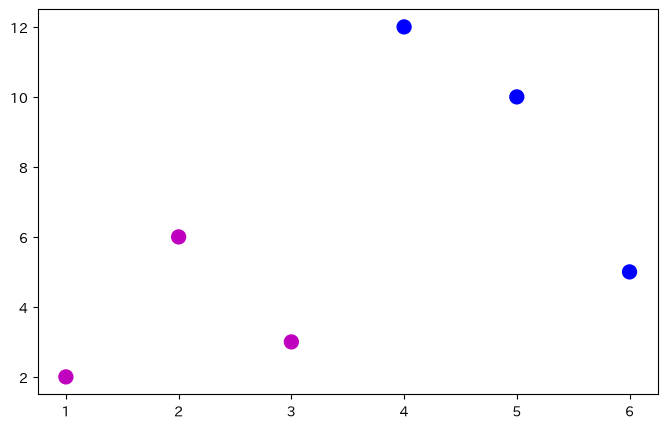

In [6]:
x = [1, 2, 3, 4, 5, 6]
y = [2, 6, 3, 12, 10, 5]

mycolors = ['m'] * 3 + ['b'] * 3
print(mycolors)

plt.figure(figsize=(8, 5))
plt.scatter(x, y, marker='o', s=100, color=mycolors)
plt.show()

### 要素を書き換える

- `リスト名[番号] = 新しい値` で、その番号の要素だけを書き換える

In [7]:
mylist = ['y'] * len(data)
mylist[0] = 'r'

print(mylist)

['r', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y']


- 先頭は `[0]`、最後は `[-1]` と書ける

▶ **演習**：`リストの作成と参照基礎004`

- リストの `リストの作成と参照基礎006`〜`010` は **numpy の配列（np.array）**を使う**発展編**の問題（第４講 I-1）。できる人だけ挑戦する（解かなくても課題には困らない）

## U-1 for 文の基本

```python
for 変数 in リスト:
    くり返す処理
```

- リストの**先頭から順に**要素を1つ取り出して `変数` に入れ、字下げした部分を実行する。これを最後の要素までくり返す

In [8]:
fruits = ['りんご', 'みかん', 'ぶどう']

for f in fruits:
    print(f)

りんご
みかん
ぶどう


- 1回目は `f` に `'りんご'`、2回目は `'みかん'`、3回目は `'ぶどう'` が入る
- 変数の名前（ここでは `f`）は自由に決めてよい。`k`、`x`、`fruit` など
- 数と文字が混ざったリストでも、同じように取り出せる

In [9]:
mylist = [11, 22, 'abc', 33]

for k in mylist:
    print(k)

11
22
abc
33


▶ **演習**：`for文基礎001`

## U-2 コロンと字下げ

- 1行目の最後に **`:`（コロン）** を付ける
- くり返す処理は、行の先頭に**半角スペース4つ**を入れて**字下げ（インデント）**する。Jupyter では `:` の後で改行すると自動で字下げされる
- 字下げした行だけがくり返される。字下げをやめた行は、くり返しが**終わった後に1回だけ**実行される

In [10]:
for f in fruits:
    print(f + 'が好き')
    print('---')
print('おわり')

りんごが好き
---
みかんが好き
---
ぶどうが好き
---
おわり


| エラーの最後の行 | 原因 | 直し方 |
|---|---|---|
| `SyntaxError: expected ':'` | 1行目の最後の `:` を忘れた | `:` を付ける |
| `IndentationError: expected an indented block` | くり返す処理を字下げしていない | 行の先頭にスペース4つ |
| `IndentationError: unexpected indent` | 字下げしなくてよい行を字下げした | 余分なスペースを消す |

- 字下げは `Tab` キーでも入る。全角スペースは使わない（見た目では区別できないので注意）

- グラフの命令も、字下げすればくり返しの中に書ける。下は、3年分のラーメンの外食費の折れ線を for で重ねたもの（3回くり返したので、線が3本になる）

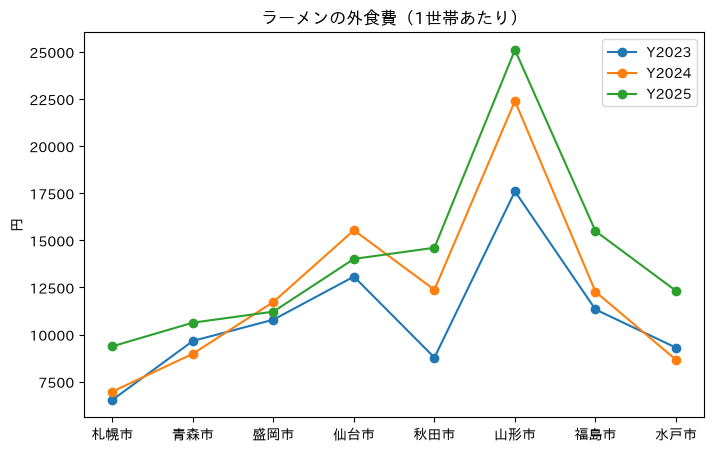

In [11]:
df_ramen = pd.read_excel('dsa2026data.xlsx', sheet_name='ramen')
top = df_ramen.head(8)

plt.figure(figsize=(8, 5))
for year in ['Y2023', 'Y2024', 'Y2025']:
    plt.plot(top['city'], top[year], marker='o', label=year)
plt.title('ラーメンの外食費（1世帯あたり）')
plt.ylabel('円')
plt.legend()
plt.show()

▶ **演習**：`for文応用001`

## U-3 くり返しの中で計算する

- 取り出した要素を使って計算できる。`**` は「〜乗」（`3 ** 2` は 3 の2乗）

In [12]:
mylist = [0, 1, 2, 3, 4, 5, 6]

for k in mylist:
    print(k ** 2)

0
1
4
9
16
25
36


▶ **演習**：`for文基礎002`

- Excel から取り出した列も、リストと同じように for で取り出せる

In [13]:
for r in df['降水量']:
    print(r, 'mm')

180.0 mm
114.5 mm
168.0 mm
54.0 mm
128.0 mm
57.0 mm
376.5 mm
42.0 mm
292.0 mm
144.5 mm
246.5 mm
262.5 mm


- 合計を数える：くり返しの前に `total = 0` を作り、くり返しの中で足していく

In [14]:
total = 0
for r in df['降水量']:
    total = total + r
print('1年間の降水量', total, 'mm')
print('np.sum でも同じ', np.sum(df['降水量']))

1年間の降水量 2065.5 mm
np.sum でも同じ 2065.5


## U-4 range：番号でくり返す

- `range(5)` は `0, 1, 2, 3, 4`（**0 から始まり、5 は入らない**）
- `range(1, 13)` は `1, 2, …, 12`（1 から 12 まで）
- 「何番目か」を使いたいときは、`range(len(リスト))` で**番号**を取り出し、`リスト[番号]` で要素を取り出す

In [15]:
for i in range(5):
    print(i)

0
1
2
3
4


In [16]:
for i in range(len(fruits)):
    print(i, fruits[i])

0 りんご
1 みかん
2 ぶどう


- リストの番号は **0 から**始まる（第２講）。`fruits[0]` が `'りんご'`

## U-5 くり返しでリストを作る

- `リスト名.append(値)` で、リストの**最後に**要素を1つ追加する
- 空のリスト `[]` から始めて、`append` で1つずつ足していくことが多い

In [17]:
emptylist = []
emptylist.append('abc')
emptylist.append(123)

print(emptylist)

['abc', 123]


- 文字列と数値のように、**種類の違う値**を1つのリストに入れてもよい

▶ **演習**：`リストの作成と参照基礎005`

- くり返しの中で `append` を使うと、計算した値を1つずつ足したリストが作れる
- 例：降水量を mm から cm に直したリストを作る

In [18]:
rain_cm = []
for r in df['降水量']:
    rain_cm.append(r / 10)
print(rain_cm)

[18.0, 11.45, 16.8, 5.4, 12.8, 5.7, 37.65, 4.2, 29.2, 14.45, 24.65, 26.25]


## U-6 くり返しでグラフを描く

- 5教科の平均点を for で1つずつ計算し、リストに集めてから棒グラフにする

[np.float64(66.76666666666667), np.float64(67.36666666666666), np.float64(62.233333333333334), np.float64(75.23333333333333), np.float64(71.36666666666666)]


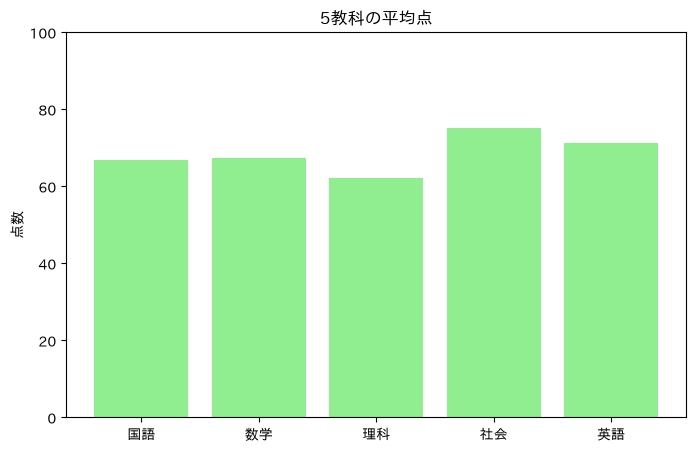

In [19]:
df_exam = pd.read_excel('dsa2026data.xlsx', sheet_name='exam')
subjects = ['国語', '数学', '理科', '社会', '英語']

means = []
for s in subjects:
    means.append(np.mean(df_exam[s]))
print(means)

plt.figure(figsize=(8, 5))
plt.bar(subjects, means, color='lightgreen')
plt.ylim(0, 100)
plt.title('5教科の平均点')
plt.ylabel('点数')
plt.show()

- 第９講 AB-5 のエラーバーも、平均と標準偏差を for で集めれば短く書ける。教科が増えても、`subjects` に足すだけでよい

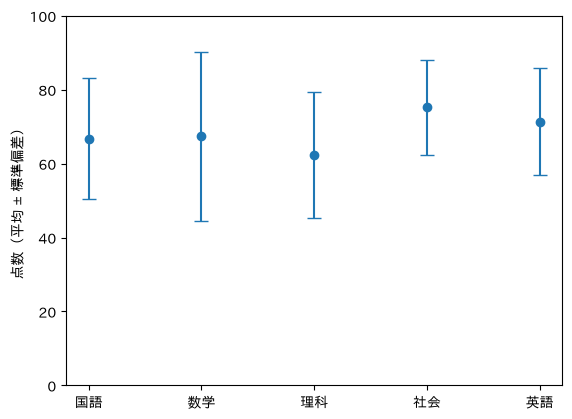

In [20]:
means = []
stds = []
for s in subjects:
    means.append(np.mean(df_exam[s]))
    stds.append(np.std(df_exam[s]))

plt.errorbar(subjects, means, yerr=stds, fmt='o', capsize=5)
plt.ylim(0, 100)
plt.ylabel('点数（平均 ± 標準偏差）')
plt.show()

▶ **演習**：`for文応用002`

### 使ってみよう
- `subjects` から `'理科'` を消すと、グラフはどうなるか
- U-6 の平均点のプログラムを、**最高点**（`np.max`）の棒グラフに変えてみよう

In [21]:
# ここで試してみよう

## U-7 散布図の点に名前を付ける

第８講 V-1 の `plt.text(x, y, '文字')` は、1回で1つの文字を書く。点が30個あれば30回 → for でまとめる。

- `worldbank` シートは、人口の多い30か国の一人あたり GDP と平均寿命
- 点が30個あるので、国の名前を for で30回書く
- GDP は国による差が大きいので、横軸を**対数目盛**（`plt.xscale('log')`：1目盛りごとに10倍）にして点を広げている

In [22]:
df_wb = pd.read_excel('dsa2026data.xlsx', sheet_name='worldbank')
df_wb.head()

,country,一次所得支払,一人あたりGDP,出生時平均寿命,人口
0,IND,-5.127827e+10,2591.991661,72.235000,1450935791
1,CHN,-1.071092e+11,13293.116227,78.017000,1408975000
2,USA,-6.868400e+10,86169.664158,78.890244,340003797
3,IDN,-3.581538e+10,4925.436450,71.288000,283487931
4,PAK,-9.622895e+09,1479.477552,67.799000,251269164


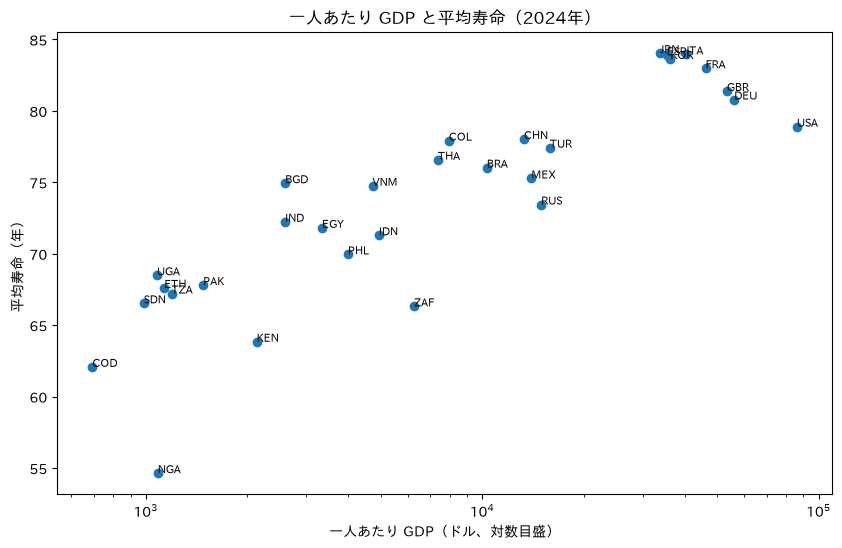

In [23]:
gdp = df_wb['一人あたりGDP']
life = df_wb['出生時平均寿命']
country = df_wb['country']

plt.figure(figsize=(10, 6))
plt.scatter(gdp, life)
for i in range(len(df_wb)):
    plt.text(gdp[i], life[i], country[i], fontsize=8)
plt.xscale('log')
plt.title('一人あたり GDP と平均寿命（2024年）')
plt.xlabel('一人あたり GDP（ドル、対数目盛）')
plt.ylabel('平均寿命（年）')
plt.show()

- `JPN` が日本。右上（豊かで長生き）にある
- 国の名前は3文字の略称（`USA`：アメリカ、`CHN`：中国、`IND`：インド、`NGA`：ナイジェリアなど）

### 使ってみよう
- 日本だけ赤い文字にするには？（ヒント：次回の if 文を使う。先に考えてみよう）
- `plt.text` の `fontsize=8` を変えたり、`ha='center'` を付けたりして、見やすくしてみよう

In [24]:
# ここで試してみよう

---
# W. 発展（できる人だけ）

## W-1 番号と値を同時に取り出す

- `enumerate(リスト)` を使うと、**番号と値**を一度に取り出せる。`range(len(…))` と同じことを短く書ける
- `zip(リスト1, リスト2)` を使うと、2つのリストから**同じ番号の要素を組にして**取り出せる

In [25]:
for i, f in enumerate(fruits):
    print(i, f)

for m, r in zip(df['月'], df['降水量']):
    print(m, '月', r, 'mm')

0 りんご
1 みかん
2 ぶどう
1 月 180.0 mm
2 月 114.5 mm
3 月 168.0 mm
4 月 54.0 mm
5 月 128.0 mm
6 月 57.0 mm
7 月 376.5 mm
8 月 42.0 mm
9 月 292.0 mm
10 月 144.5 mm
11 月 246.5 mm
12 月 262.5 mm


---
# まとめ

| やりたいこと | 書き方 |
|---|---|
| **以下はリスト** | |
| 同じものを並べる | `['y'] * 5`、`['y'] * len(data)` |
| 個数を数える | `len(リスト)` |
| 書き換える | `リスト[番号] = 新しい値`（最後は `[-1]`） |
| **以下は for 文** | |
| リストの要素を1つずつ取り出す | `for k in リスト:`（`:` を忘れない） |
| くり返す処理 | 行の先頭に**半角スペース4つ**（字下げ） |
| 番号でくり返す | `for i in range(len(リスト)):`、要素は `リスト[i]` |
| `range` | `range(5)` → 0〜4、`range(1, 13)` → 1〜12 |
| 最後に追加する | `リスト.append(値)` |
| リストを作る | `new = []` → くり返しの中で `new.append(値)` |
| 2乗 | `k ** 2` |
| 点ごとに文字を書く | `for i in range(len(x)):` の中で `plt.text(x[i], y[i], 名前[i])` |

次回（第13講）は **if 文**（条件で処理を分ける）と、**関数**（処理に名前を付ける）。